# CS753 Assignment 1

## Task 1
Implementation of a basic Page Rank algorithm

Set up the modules

In [1]:
import numpy as np
import pandas as pd
import scipy as sp

Some functions for reading and wrangling the data

In [2]:
def read_adjacency_dataset(filename, N):
    with open(filename) as f:
        lines = f.readlines()

    M = sp.sparse.lil_matrix((N, N))

    for l in lines:
        edge_indices = l.strip("\n").split('\t')
        source, dest = int(edge_indices[0]), int(edge_indices[1])
        M[dest, source] = 1 # Source along cols, destinations along rows

    M_csr = M.tocsr()

    return M_csr


def csr_mat_to_col_stochastic(M_csr):
    col_sums = np.array(M_csr.sum(axis=0)).flatten()
    col_sums[col_sums == 0] = 1

    res =  M_csr.multiply(1 / col_sums)

    return res.tocsr()

**(A) Implementing a basic Pagerank algorithm with iterative form**

Get the M matrix

In [3]:
N = 875713

M_csr = read_adjacency_dataset("web-Google-final.txt", N)

M = csr_mat_to_col_stochastic(M_csr)

Function for a basic Page Rank implementation

In [4]:
from timeit import default_timer as timer

def page_rank(M, max_iter=1000, eps=0.02):
    start = timer()
    
    errs = []
    scores = []
    
    N = M.shape[0]

    r_prev = np.ones(shape=(N, 1)) / N

    num_iters = -1
    
    for i in range(1, max_iter):
        r_curr = M.dot(r_prev)
        scores.append(r_curr)
        
        this_error = np.linalg.norm(r_curr - r_prev, ord=1)
        errs.append(this_error)
        
        if this_error < eps:
            num_iters = i
            break
        
        r_prev = r_curr 
    
    if num_iters == -1:
        print(f"Didn't converge in {max_iter} iterations")
    else:
        print(f"Number of iterations: {num_iters}") 
    print(f"Took {timer() - start:.2f} seconds to complete")

    
    return r_prev, scores, errs, num_iters

Now run the iterative method

In [5]:
r, scores, errs, i_finish = page_rank(M)

Number of iterations: 49
Took 1.28 seconds to complete


Plot the iteration errors to verify it's converging smoothly

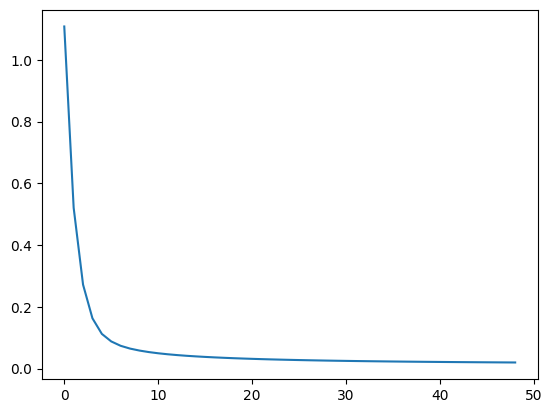

In [6]:
import matplotlib.pyplot as plt

plt.plot(errs)

**(B) extracting top 10 rank scores**

In [7]:
def top_10_ranks(r):
    r_flat = r.flatten()
    r_top_10_IDs = np.argsort(r_flat)[-10:]
    r_top_10_scores = r_flat[r_top_10_IDs]
    
    return r_top_10_IDs, r_top_10_scores

In [8]:
r_top_10_IDs, r_top_10_scores = top_10_ranks(r)

Quickly write the results to Latex for my report

In [9]:
import pandas as pd

def top_ranks_to_latex(top_IDs, top_scores):
    df = pd.DataFrame({
        "Node ID": top_IDs,
        "Node Score": top_scores
    })
    
    df_tex = df.to_latex(index=False, float_format="%.2e")
    print(df_tex)
    
top_ranks_to_latex(r_top_10_IDs, r_top_10_scores)   

\begin{tabular}{rr}
\toprule
Node ID & Node Score \\
\midrule
41909 & 2.41e-04 \\
1536 & 2.49e-04 \\
791675 & 2.95e-04 \\
865192 & 3.20e-04 \\
577518 & 3.60e-04 \\
779617 & 4.28e-04 \\
370344 & 5.14e-04 \\
544138 & 5.14e-04 \\
24576 & 5.14e-04 \\
747106 & 5.30e-04 \\
\bottomrule
\end{tabular}



Print out the top 10 nodes and their scores

In [10]:
print("Top 10 IDs")
print(r_top_10_IDs)
print("Top 10 Scores")
print(r_top_10_scores)

Top 10 IDs
[ 41909   1536 791675 865192 577518 779617 370344 544138  24576 747106]
Top 10 Scores
[0.00024116 0.00024918 0.00029454 0.00031989 0.00035961 0.00042832
 0.00051429 0.00051429 0.00051429 0.00052984]


Plot the rank scores to get an idea of the distribution

In [11]:
def plot_r_sorted(r):
    plt.plot(np.sort(r.flatten()))

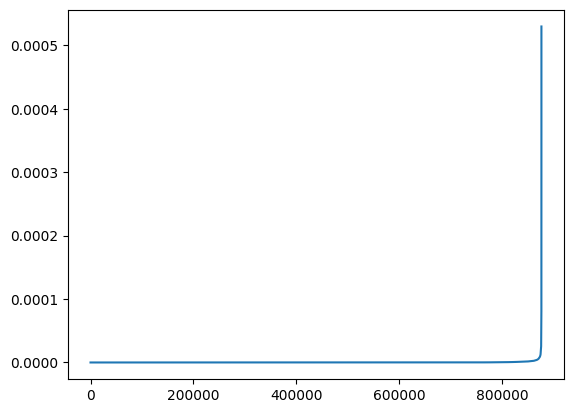

In [12]:
plot_r_sorted(r)

You can see that there is a bunch of score 'accumulating' in just a few nodes

## Task 2

**(A) Finding dead-end nodes**
* Virtually comes down to finding the nodes with no outgoing links. Can simply do the sum down the columns to identify these nodes

In [30]:
def remove_dead_ends(M):
    # Removes dead end nodes from M, and then fixes it back to col stochastic form
    
    def remove_dead_ends_helper(M_in):
        M_summed = np.sum(M_in, axis=0)
        dead_end_indices = np.argwhere(M_summed == 0)[:, 1]
        non_dead_end_indices = np.argwhere(M_summed > 0)[:, 1]
        
        # The below doesn't actually work does it?
        M_no_dead_ends = M_in[:, non_dead_end_indices]
        M_no_dead_ends = M_no_dead_ends[non_dead_end_indices, :]
        
        M_no_dead_ends = csr_mat_to_col_stochastic(M_no_dead_ends)
        
        return M_no_dead_ends, non_dead_end_indices, dead_end_indices
    
    M_in = M
    
    for i in range(1000):
        M_nde, ndei, dei = remove_dead_ends_helper(M_in)
        
        print(np.sum(np.sum(M_nde, axis=0) == 0))
        
        if np.sum(np.sum(M_nde, axis=0) == 0) == 0:
            return M_nde, ndei, dei
        
        M_in = M_nde
    
    return None

M_no_dead_ends, non_dead_end_indices, dead_end_indices = remove_dead_ends(M)

33080
6663
1734
478
164
73
39
34
20
8
4
4
4
2
1
1
2
0


Finding the number of dead ends

In [83]:
np.sum(np.sum(M_no_dead_ends, axis=0) == 0)

# 30000 is non trivial. What is going on?

np.int64(33080)

In [89]:
np.sum(np.sum(M[np.ix_(non_dead_end_indices,non_dead_end_indices)], axis=0) == 0)

np.int64(33080)

In [79]:
print(f"The number of dead-end nodes was {len(dead_end_indices)}")

The number of dead-end nodes was 187880


**(B) Calculating leaked page rank scores**

In [18]:
r_no_dead_ends, r_scores_no_dead_ends, errs_no_dead_ends, i_finish_no_dead_ends = page_rank(M_no_dead_ends)

# Now doesn't converge

Didn't converge in 1000 iterations
Took 12.01 seconds to complete


np.float64(0.027234788947583004)

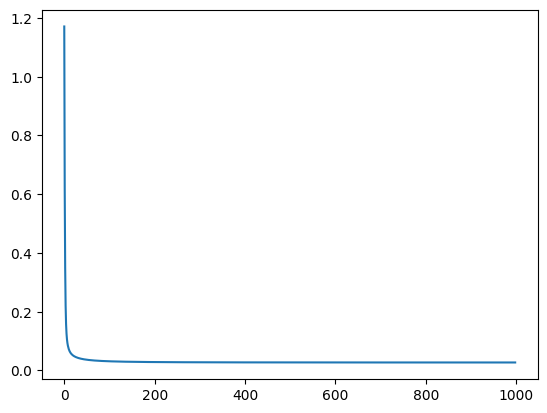

In [19]:
plt.plot(errs_no_dead_ends)

errs_no_dead_ends[-2]

In [20]:
r_scores_no_dead_ends_arr = np.squeeze(np.array(r_scores_no_dead_ends))
r_scores = np.squeeze(np.array(scores))

In [21]:
r_scores.shape

(49, 875713)

In [22]:
len(r_scores_no_dead_ends)

999

In [23]:
r_scores_no_dead_ends_arr.shape

(999, 687833)

In [25]:
num_iters = r_scores.shape[0]
leaked_scores = r_scores[:, non_dead_end_indices] - r_scores_no_dead_ends_arr[:num_iters, :]

In [28]:
leaked_scores.shape

(49, 687833)

In [29]:
leaked_scores_totals = leaked_scores.sum(axis=1)
leaked_scores_totals_abs = np.abs(leaked_scores_totals)

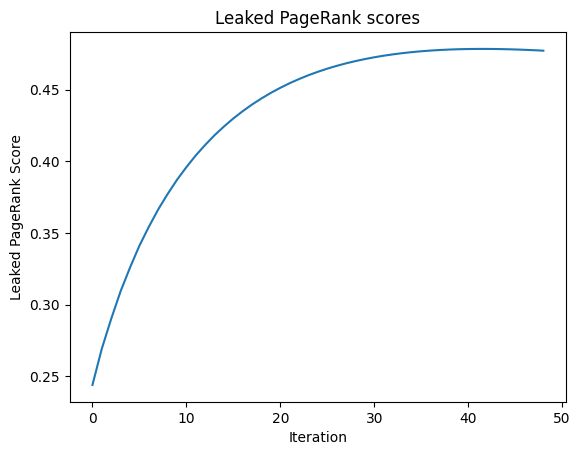

In [30]:
plt.plot(leaked_scores_totals_abs)
plt.title("Leaked PageRank scores")
plt.xlabel("Iteration")
plt.ylabel("Leaked PageRank Score")
plt.savefig("leaked_page_rank.png", dpi=300)

# Task 3

**(A) Adding teleportation**

In [31]:
def page_rank_improved(M, max_iter=1000, eps=0.02, beta=0.9):
    """
    Does page rank to handle both dead ends and spider traps
    """
    # First remove the dead ends
    M, _, _ = remove_dead_ends(M)

    N = M.shape[0]
    r_prev = np.ones(shape=(N, 1)) / N
    
    errs = []
    scores = []
    
    num_iters = -1
    
    start = timer()

    for i in range(max_iter):
        r_curr = beta * M.dot(r_prev) # Step 1
        
        S = np.sum(r_curr) # Step 2
        
        scores.append(r_curr)
        
        r_curr = r_curr + (1 - S) / N # Step 3
        
        this_error = np.linalg.norm(r_curr - r_prev, ord=1)
        errs.append(this_error)

        if this_error < eps:
            num_iters = i+1
            break

        r_prev = r_curr

    if num_iters == -1:
            print(f"Didn't converge in {max_iter} iterations")
    else:
        print(f"Number of iterations: {num_iters}")
    print(f"Took {timer() - start:.2f} seconds to complete")

    return r_prev, scores, errs, num_iters

**(B) Running teleportation code**

In [32]:
r_improved, scores_improved, errs_improved, i_finish_improved = page_rank_improved(M)

Number of iterations: 12
Took 0.15 seconds to complete


In [33]:
top_ranks_to_latex(*top_10_ranks(r_improved))

\begin{tabular}{rr}
\toprule
Node ID & Node Score \\
\midrule
383006 & 8.52e-04 \\
396493 & 8.61e-04 \\
439594 & 8.66e-04 \\
434172 & 8.75e-04 \\
302606 & 8.84e-04 \\
590614 & 8.93e-04 \\
470014 & 1.02e-03 \\
128304 & 1.04e-03 \\
422487 & 1.04e-03 \\
33052 & 1.06e-03 \\
\bottomrule
\end{tabular}



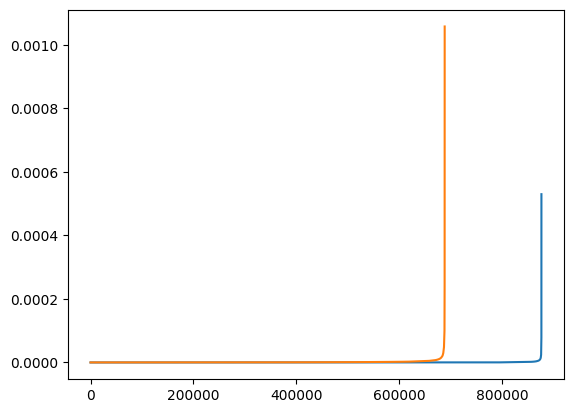

In [34]:
plt.plot(np.sort(r.flatten()))
plt.plot(np.sort(r_improved.flatten()))

You can see in the above, that there the accumulation in the rank score is a bit more subdued - unlike what we saw with the previous case

In [37]:
beta_vals = [1, 0.9, 0.8, 0.7, 0.6]
iterations_vals = []
beta_r_scores = []

for B in beta_vals:
    r, _, _, iters = page_rank_improved(M, beta=B)

    beta_r_scores.append(r)
    
    iterations_vals.append(iters)
    
    print(f"\nFor beta {B}, num iterations is: {iters}")

    print(f"mean rank: {np.mean(r):.2e}\n")


Number of iterations: -1
Took 15.15 seconds to complete

For beta 1, num iterations is: -1
mean rank: 1.45e-06

Number of iterations: 12
Took 0.27 seconds to complete

For beta 0.9, num iterations is: 12
mean rank: 1.45e-06

Number of iterations: 8
Took 0.12 seconds to complete

For beta 0.8, num iterations is: 8
mean rank: 1.45e-06

Number of iterations: 6
Took 0.11 seconds to complete

For beta 0.7, num iterations is: 6
mean rank: 1.45e-06

Number of iterations: 5
Took 0.07 seconds to complete

For beta 0.6, num iterations is: 5
mean rank: 1.45e-06



Plotting beta values and their convergence rates

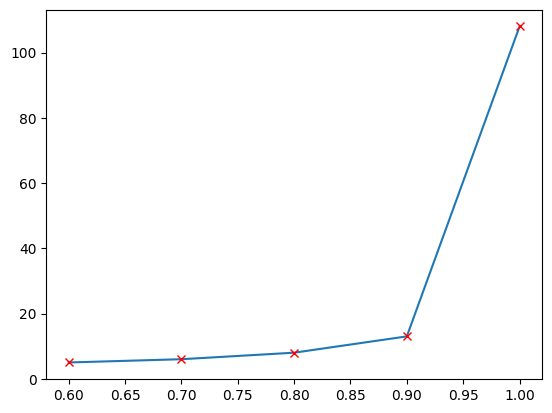

In [269]:
plt.plot(beta_vals, iterations_vals, marker="x", markeredgecolor = "red")

Clearly what is happening that an increase of the Beta value increases the number of iterations for the algo to finish

Writing results to latex for my report

In [317]:
df_beta = pd.DataFrame({
    "Teleportation Probability ($\\beta$)": beta_vals,
    "Iterations to Converge": iterations_vals
})

tex = df_beta.to_latex(index=False, float_format="%.1f")

print(tex)

\begin{tabular}{rr}
\toprule
Teleportation Probability (\beta) & Iterations to Convergence \\
\midrule
1.0 & 108 \\
0.9 & 13 \\
0.8 & 8 \\
0.7 & 6 \\
0.6 & 5 \\
\bottomrule
\end{tabular}

